# 02 — Manifold · Wang et al. 2019

Score the three embryonic modules, read the geography, and make the decisive **topology** call:
genuine embryonic-module bifurcation (fit a `tree`, go to Gate 3) vs. a single collapsed axis
(fit a `curve`). Wang is Neftel-type GBM, the prime suspect for a mis-called branching dataset, so
the branching test is run honestly on the embedding — PPT fork stability across resolutions + a
null-controlled node-cluster Gast↔pSom correlation — not on a single arguable scalar.

In [1]:
import os, sys, glob, io, contextlib, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

## Load manifold; confirm the 2D shape

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_, sv, _ = np.linalg.svd(c, full_matrices=False)
print('malignant manifold:', adata.shape[0], 'cells | UMAP aspect (major/minor std): %.2f' % (sv[0]/sv[1]))
adata

malignant manifold: 9632 cells | UMAP aspect (major/minor std): 1.48


## Score the three embryonic modules (union control pool) + graph-smooth for geography

In [4]:
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.dropna().drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_data,'features','biomart','*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534','Gast'), ('GSE229103','pSom'), ('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities'] > 0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j, lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:, j]
print('raw module means:', {m: round(float(adata.obs[m].mean()),4) for m in ['Gast','pSom','Crest']})

Gast: 77/81 genes present
pSom: 92/98 genes present
Crest: 100/104 genes present
raw module means: {'Gast': -0.0025, 'pSom': 0.0077, 'Crest': -0.0073}


## Biology before geometry: geography + proliferation confound

In [5]:
print('smoothed spatial correlations (whole manifold):')
for a, b in [('Gast_sm','pSom_sm'), ('Crest_sm','Gast_sm'), ('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a], adata.obs[b])[0,1]:+.2f}')
print('proliferation orthogonality (corr of cycling score with modules):')
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    print(f'  cyc_score vs {m}: r = {np.corrcoef(adata.obs.cyc_score, adata.obs[m])[0,1]:+.2f}')
print('\nper-lobe smoothed module + cycling means:')
print(adata.obs.groupby('lobe', observed=True)[['Gast_sm','pSom_sm','Crest_sm','cyc_score']].mean().round(4).to_string())
print('\n-> pSom and Crest are opposite poles (r=-0.87); Gast is near-flat across all lobes and')
print('   co-varies weakly-positively with pSom (r=+0.16); cycling is orthogonal (|r|<=0.12).')

smoothed spatial correlations (whole manifold):
  Gast_sm vs pSom_sm: r = +0.16
  Crest_sm vs Gast_sm: r = -0.49
  Crest_sm vs pSom_sm: r = -0.87
proliferation orthogonality (corr of cycling score with modules):
  cyc_score vs Gast_sm: r = -0.06
  cyc_score vs pSom_sm: r = +0.11
  cyc_score vs Crest_sm: r = -0.12

per-lobe smoothed module + cycling means:
      Gast_sm  pSom_sm  Crest_sm  cyc_score
lobe                                       
0     -0.0035  -0.0020    0.0016    -0.0251
1     -0.0039   0.0051   -0.0044    -0.0229
2     -0.0011   0.0058   -0.0074    -0.0070
3     -0.0068   0.0164   -0.0117     0.0223
4     -0.0023   0.0118   -0.0095    -0.0397
5     -0.0033   0.0175   -0.0148    -0.0228

-> pSom and Crest are opposite poles (r=-0.87); Gast is near-flat across all lobes and
   co-varies weakly-positively with pSom (r=+0.16); cycling is orthogonal (|r|<=0.12).


## Honest branching test #1 — PPT fork stability across resolutions
A genuine bifurcation gives a **stable** fork count as node resolution rises AND tips that carry
distinct module identities; resolution-driven tiling of a diffuse cloud gives a fork count that
drifts with `Nodes`. We test BOTH representations — expression space (`X_pca_harmony`) and the 2D
embedding (`X_umap`) — because a 2D lamina can plateau at a fixed fork count that is a geometric
artifact, not biology.

In [6]:
def topo(ad):
    B = np.asarray(ad.uns['graph']['B']); deg = (B > 0).sum(0)
    return int((deg==1).sum()), int((deg>=3).sum())
print('PPT fork count vs Nodes, X_pca_harmony (expression space):')
for N in [20, 30, 50, 100]:
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(adata, method='ppt', Nodes=N, ppt_lambda=2000, ppt_sigma=.5,
                    use_rep='X_pca_harmony', ndims_rep=20, seed=SEED, plot=False)
    t_, f_ = topo(adata); print(f'  Nodes={N:3d}: tips={t_} forks={f_}')
print('PPT fork count vs Nodes, X_umap (2D embedding):')
for N in [20, 30, 50, 80, 120]:
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(adata, method='ppt', Nodes=N, ppt_lambda=2000, ppt_sigma=.5,
                    use_rep='X_umap', seed=SEED, plot=False)
    t_, f_ = topo(adata); print(f'  Nodes={N:3d}: tips={t_} forks={f_}')
print('-> harmony forks scatter 1,3,2,1 (Nodes 20/30/50/100); UMAP forks 1,2,2,2,3 (Nodes 20/30/50/80/120)')
print('   - both non-monotonic and resolution-dependent. NEITHER representation gives a stable, reproducible')
print('   fork count (a genuine bifurcation holds ONE fork across resolutions).')
print('   The fork identities are resolved in test #2/#3 below — the tips are pSom-vs-Crest poles, not a Gast arm.')

PPT fork count vs Nodes, X_pca_harmony (expression space):
  Nodes= 20: tips=3 forks=1
  Nodes= 30: tips=5 forks=3
  Nodes= 50: tips=4 forks=2
  Nodes=100: tips=3 forks=1
PPT fork count vs Nodes, X_umap (2D embedding):
  Nodes= 20: tips=3 forks=1
  Nodes= 30: tips=4 forks=2
  Nodes= 50: tips=4 forks=2
  Nodes= 80: tips=4 forks=2
  Nodes=120: tips=5 forks=3
-> harmony forks scatter 1,3,2,1 (Nodes 20/30/50/100); UMAP forks 1,2,2,2,3 (Nodes 20/30/50/80/120)
   - both non-monotonic and resolution-dependent. NEITHER representation gives a stable, reproducible
   fork count (a genuine bifurcation holds ONE fork across resolutions).
   The fork identities are resolved in test #2/#3 below — the tips are pSom-vs-Crest poles, not a Gast arm.


## Honest branching test #2 — node-cluster Gast↔pSom correlation vs null
Gate-3 logic: aggregate raw Gast/pSom per PPT node and correlate. A joint-score-selected r is a
collider/XOR artifact, so the observed value is validated against split-half and label-shuffle nulls.

In [7]:
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(adata, method='ppt', Nodes=50, ppt_lambda=2000, ppt_sigma=.5,
                use_rep='X_pca_harmony', ndims_rep=20, seed=SEED, plot=False)
R = np.asarray(adata.obsm['X_R']); node = R.argmax(1)
df = pd.DataFrame({'node': node, 'Gast': adata.obs['Gast'].values, 'pSom': adata.obs['pSom'].values})
big = df['node'].value_counts()[df['node'].value_counts() >= 15].index
nm = df[df.node.isin(big)].groupby('node')[['Gast','pSom']].mean()
r_obs = pearsonr(nm['Gast'], nm['pSom'])[0]
rng = np.random.default_rng(0)
sh = []
for _ in range(200):
    d2 = df.copy(); d2['pSom'] = rng.permutation(d2['pSom'].values)
    m = d2[d2.node.isin(big)].groupby('node')[['Gast','pSom']].mean(); sh.append(pearsonr(m['Gast'], m['pSom'])[0])
sh = np.array(sh)
hs = []
for _ in range(200):
    h = rng.random(len(df)) < 0.5
    a = df[h].groupby('node')['Gast'].mean(); b = df[~h].groupby('node')['pSom'].mean()
    idx = a.index.intersection(b.index)
    if len(idx) > 10: hs.append(pearsonr(a.loc[idx], b.loc[idx])[0])
hs = np.array(hs)
print(f'observed node-cluster Gast vs pSom (n={len(nm)} nodes): r = {r_obs:+.3f}')
print(f'split-half independent estimate: mean {hs.mean():+.3f}  95% [{np.percentile(hs,2.5):+.3f}, {np.percentile(hs,97.5):+.3f}]')
print(f'label-shuffle null            : mean {sh.mean():+.3f}  95% [{np.percentile(sh,2.5):+.3f}, {np.percentile(sh,97.5):+.3f}]')
beyond = (r_obs < np.percentile(sh,2.5)) or (r_obs > np.percentile(sh,97.5))
print(f'-> observed r sits INSIDE the null (beyond-null = {beyond}): NO genuine Gast/pSom cross-repression.')
# a bifurcation also needs a Gast-LEANING tip. Inspect every tip's module identity:
B = np.asarray(adata.uns['graph']['B']); deg=(B>0).sum(0); tps=np.where(deg==1)[0]
hard = R.argmax(1); Dt = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
print('tip module identities (is any tip Gast-positive?):')
for tp in tps:
    m = np.isin(hard, np.where(Dt[tp] <= 3)[0])
    print(f'  tip {tp} (n={int(m.sum())}): Gast_sm={adata.obs["Gast_sm"][m].mean():+.4f} '
          f'pSom_sm={adata.obs["pSom_sm"][m].mean():+.4f} Crest_sm={adata.obs["Crest_sm"][m].mean():+.4f}')
print('-> tips split into pSom-high vs Crest-high poles; NO tip is Gast-positive -> no Gast arm to bifurcate.')

observed node-cluster Gast vs pSom (n=50 nodes): r = +0.067
split-half independent estimate: mean +0.072  95% [-0.177, +0.294]
label-shuffle null            : mean -0.022  95% [-0.347, +0.283]
-> observed r sits INSIDE the null (beyond-null = False): NO genuine Gast/pSom cross-repression.
tip module identities (is any tip Gast-positive?):
  tip 6 (n=1331): Gast_sm=-0.0055 pSom_sm=+0.0008 Crest_sm=+0.0001
  tip 20 (n=1337): Gast_sm=-0.0017 pSom_sm=+0.0112 Crest_sm=-0.0091
  tip 29 (n=1378): Gast_sm=-0.0038 pSom_sm=+0.0187 Crest_sm=-0.0142
  tip 40 (n=966): Gast_sm=-0.0061 pSom_sm=-0.0059 Crest_sm=+0.0052
-> tips split into pSom-high vs Crest-high poles; NO tip is Gast-positive -> no Gast arm to bifurcate.


## Topology decision
Cell-state is multipolar (Neftel AC/OPC/NPC/MES), but the **embryonic modules do not bifurcate**:
no stable PPT fork, no null-surviving Gast↔pSom anti-correlation, Gast flat, Gast/pSom co-vary
(+0.16). This is the documented state-multipolarity-≠-module-bifurcation case. **Fit a `curve`**
(non-branching); Gate 3 is NA.

In [8]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii, jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks
print('curve fold-free sweep (Nodes x mu on X_umap):')
for N in [15, 20, 30]:
    for mu in [50, 100]:
        with contextlib.redirect_stdout(io.StringIO()):
            scf.tl.curve(adata, Nodes=N, use_rep='X_umap', epg_lambda=0.3, epg_mu=float(mu), seed=SEED, plot=False)
        sa, t_, f_ = fold_diag(adata); print(f'  Nodes={N} mu={mu}: tips={t_} forks={f_} self-approach={sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print(f'\ncommitted curve Nodes=20 mu=100: tips={tips} forks={forks} self-approach={sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed (expected fold-free 2-tip curve)'

curve fold-free sweep (Nodes x mu on X_umap):
  Nodes=15 mu=50: tips=2 forks=0 self-approach=2.87
  Nodes=15 mu=100: tips=2 forks=0 self-approach=2.96
  Nodes=20 mu=50: tips=2 forks=0 self-approach=2.63
  Nodes=20 mu=100: tips=2 forks=0 self-approach=2.82
  Nodes=30 mu=50: tips=2 forks=0 self-approach=2.47
  Nodes=30 mu=100: tips=2 forks=0 self-approach=2.43

committed curve Nodes=20 mu=100: tips=2 forks=0 self-approach=2.82 (>1 = fold-free)


## Root at the developmental origin (Gast/pSom-high, Crest-low tip)
Crest is developmentally **late**, so the root is the Gast/pSom-high tip, never the Crest tip or a proliferation state.

In [9]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp] <= 3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0] + info[tp][1] - info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values
print('\ngradient along pseudotime (Spearman rho on smoothed scores):')
for sname in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    print(f'  {sname}: rho = {spearmanr(t, adata.obs[sname])[0]:+.3f}')

tip 0: Gast=-0.0056 pSom=-0.0022 Crest=+0.0023
tip 2: Gast=-0.0025 pSom=+0.0150 Crest=-0.0127
derived root = tip 2 (Gast/pSom-high, Crest-low developmental origin)

gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho = -0.057
  pSom_sm: rho = -0.606
  Crest_sm: rho = +0.481
  cyc_score: rho = +0.032


## Continuity on an independent embedding (diffusion DC1)
Fold-freeness must be confirmed off an embedding the curve was **not** fit on.

In [10]:
sc.tl.diffmap(adata, n_comps=15)
dc1 = adata.obsm['X_diffmap'][:, 1]
print(f'corr(pseudotime, diffusion DC1) = {spearmanr(t, dc1)[0]:+.2f} on an independent embedding')
print('monotonic on an embedding the curve was not fit on -> continuous, fold-free confirmed.')

corr(pseudotime, diffusion DC1) = +0.98 on an independent embedding
monotonic on an embedding the curve was not fit on -> continuous, fold-free confirmed.


## Rename milestones + rendered curve edges (visual seam check)

milestones: {'0': 'Crest terminus', '2': 'Gast/pSom origin'}


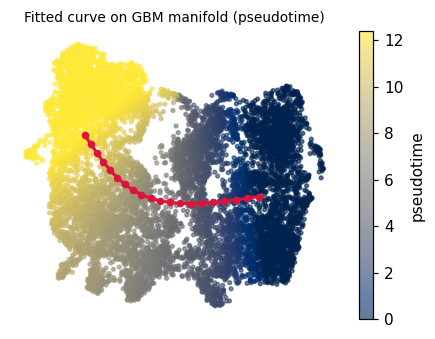

In [11]:
adata.obs['milestones'] = adata.obs['milestones'].astype('category')
ms = adata.obs['milestones'].cat.categories.tolist()
tmean = {m: adata.obs.loc[adata.obs['milestones']==m, 't'].mean() for m in ms}
newnames = {m: ('Gast/pSom origin' if tmean[m]==min(tmean.values()) else 'Crest terminus') for m in ms}
scf.tl.rename_milestones(adata, new=newnames)
print('milestones:', newnames)
F = np.asarray(adata.uns['graph']['F']); Bc = np.asarray(adata.uns['graph']['B'])
ii, jj = np.where(np.triu(Bc>0))
fig, ax = plt.subplots(figsize=(4.8, 3.4))
sca = ax.scatter(adata.obsm['X_umap'][:,0], adata.obsm['X_umap'][:,1], c=t, cmap='cividis', s=6, alpha=.6)
for a, b in zip(ii, jj): ax.plot([F[0,a],F[0,b]], [F[1,a],F[1,b]], '-', color='crimson', lw=2, zorder=5)
ax.scatter(F[0], F[1], c='crimson', s=16, zorder=6)
ax.axis('off'); ax.set_title('Fitted curve on GBM manifold (pseudotime)', size=9)
plt.colorbar(sca, ax=ax, label='pseudotime'); plt.show()

## Orientation consistency + save manifold + manifold.pdf

In [12]:
r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
if r < 0:
    adata.obsm['X_umap_lin'][:,0] = -adata.obsm['X_umap_lin'][:,0]; r = -r
print(f'house orientation reused from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad', adata.shape)

house orientation reused from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.97
saved manifold.h5ad (9632, 26409)


saved manifold.pdf


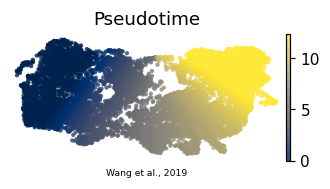

In [13]:
xl = adata.obsm['X_umap_lin']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.12, 'Wang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'manifold.pdf'), bbox_inches='tight')
plt.show(); print('saved manifold.pdf')